# 02 — Membersihkan Data

Tujuan notebook ini: membuat data yang konsisten tanpa mengarang nilai yang hilang.

Prinsip:
- file mentah tidak diubah;
- duplikat dihapus dengan aturan yang jelas;
- harga nol/tidak wajar tidak diisi dengan tebakan;
- setiap keputusan dicatat.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if (ROOT / "notebooks").exists():
    pass
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
print("Root proyek:", ROOT)

Root proyek: C:\Users\53\Documents\data sains\project saham


## 1. Snapshot: dari kolom asli ke kolom analisis

In [2]:
from src.data_loader import load_snapshot
from src.data_cleaning import clean_snapshot, snapshot_quality_report

raw = load_snapshot()
print("Sebelum:", raw.shape)

clean = clean_snapshot(raw)
print("Sesudah:", clean.shape)
new_columns = [c for c in clean.columns if c not in raw.columns]
print("Kolom turunan:", new_columns)

clean[["ticker", "company_name", "last_trade_date", "close", "volume",
       "traded", "ohlc_valid", "market_cap", "tradeable_pct", "foreign_net"]].head()

Sebelum: (963, 28)
Sesudah: (963, 34)
Kolom turunan: ['no', 'ticker', 'company_name', 'remarks', 'previous_close', 'open', 'last_trade_date', 'first_trade', 'high', 'low', 'close', 'change', 'volume', 'value', 'frequency', 'index_individual', 'offer', 'offer_volume', 'bid', 'bid_volume', 'listed_shares', 'tradeable_shares', 'weight_for_index', 'foreign_sell', 'foreign_buy', 'non_regular_volume', 'non_regular_value', 'non_regular_frequency', 'traded', 'ohlc_valid', 'market_cap', 'foreign_net', 'avg_trade_price', 'tradeable_pct']


,ticker,company_name,last_trade_date,close,volume,traded,ohlc_valid,market_cap,tradeable_pct,foreign_net
0,AADI,Adaro Andalan Indonesia Tbk.,2026-10-23,11375,10571100,True,True,88575893770000,100.0,-2416100
1,AALI,Astra Agro Lestari Tbk.,2026-10-23,9625,8207400,True,True,18525125205125,100.0,3944100
2,ABBA,Mahaka Media Tbk.,2026-10-23,30,0,False,True,118076785710,100.0,0
3,ABDA,Asuransi Bina Dana Arta Tbk.,2026-10-23,5025,31600,True,True,3119553567000,100.0,1600
4,ABMM,ABM Investama Tbk.,2026-10-23,2540,767200,True,True,6993039100000,100.0,-186600


### Catatan penting tentang `Open Price = 0`

Snapshot IDX mencatat `Open Price = 0` untuk sebagian saham yang tetap diperdagangkan.
Nilai itu diperlakukan sebagai **tidak tersedia**, bukan harga nol. Validator tidak
menghukum baris seperti itu selama harga lain konsisten.

In [3]:
zero_open = clean[(clean["volume"] > 0) & (clean["open"].fillna(0) <= 0)]
print("Saham diperdagangkan dengan Open Price 0:", len(zero_open))
zero_open[["ticker", "company_name", "open", "high", "low", "close", "volume"]].head(10)

Saham diperdagangkan dengan Open Price 0: 204


,ticker,company_name,open,high,low,close,volume
3,ABDA,Asuransi Bina Dana Arta Tbk.,0,5200,4810,5025,31600
7,ACST,Acset Indonusa Tbk.,0,73,72,73,51800
15,AEGS,Anugerah Spareparts Sejahtera Tbk.,0,47,43,44,8983500
28,ALII,Ancara Logistics Indonesia Tbk.,0,650,620,645,264600
32,AMAG,Asuransi Multi Artha Guna Tbk.,0,384,378,384,19100
33,AMAN,Makmur Berkah Amanda Tbk.,0,184,170,179,434100
35,AMFG,Asahimas Flat Glass Tbk.,0,3030,2890,3030,6500
38,AMMS,Agung Menjangan Mas Tbk.,0,110,98,104,3702400
46,APII,Arita Prima Indonesia Tbk.,0,195,184,193,14300
60,ASBI,Asuransi Bintang Tbk.,0,360,350,354,1800


In [4]:
report = snapshot_quality_report(raw, clean)
print("Duplikat ticker setelah dibersihkan:", report["duplicate_tickers"])
print("OHLC tidak wajar:", report["invalid_ohlc_rows"])
print("Saham tanpa transaksi:", report["no_trade_rows"])
print("Total nilai transaksi (Rp):", f"{report['total_value']:,.0f}")

Duplikat ticker setelah dibersihkan: 0
OHLC tidak wajar: 0
Saham tanpa transaksi: 130
Total nilai transaksi (Rp): 13,915,556,599,600


## 2. Data historis: duplikat, harga nol, dan kolom validasi

In [5]:
from src.data_loader import load_historical_prices
from src.data_cleaning import clean_historical, historical_quality_report

prices_raw = load_historical_prices()
prices = clean_historical(prices_raw)

print("Sebelum:", prices_raw.shape)
print("Sesudah:", prices.shape)
print("Harga close <= 0:", int((prices["close"] <= 0).sum()))
print("Harga adj_close <= 0:", int((prices["adj_close"] <= 0).sum()))
print("Duplikat (ticker, tanggal):", int(prices.duplicated(["ticker", "date"]).sum()))

historical_quality_report(prices)["per_ticker"]

Sebelum: (23856, 8)
Sesudah: (23856, 9)
Harga close <= 0: 0
Harga adj_close <= 0: 0
Duplikat (ticker, tanggal): 0


,Ticker,Baris,Awal,Akhir,Kelengkapan (%),Missing,Duplikat,OHLC Tidak Wajar,Volume Nol,Harga Disesuaikan Berbeda (%),Jeda > 5 Hari
0,ADRO.JK,1898,2019-01-01,2026-10-26,99.9,0,0,0,14,93.6,10
1,AKRA.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,15,96.9,10
2,ANTM.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,13,95.3,10
3,ASII.JK,1898,2019-01-01,2026-10-26,99.9,0,0,0,14,99.5,10
4,BBCA.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,15,97.8,10
5,BBRI.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,13,93.4,10
6,BMRI.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,14,98.5,10
7,GOTO.JK,1085,2022-04-11,2026-10-26,57.1,0,0,0,3,0.0,7
8,ICBP.JK,1898,2019-01-01,2026-10-26,99.9,0,0,0,13,95.9,10
9,SMGR.JK,1899,2019-01-01,2026-10-26,100.0,0,0,0,14,94.4,10


### Close vs Adj Close

`Close` adalah harga yang tertera di pasar. `Adj Close` disesuaikan untuk dividen dan
split menurut penyedia data. Untuk membandingkan return jangka panjang, gunakan `Adj Close`.
Untuk valuasi harga saat ini, gunakan `Close`.

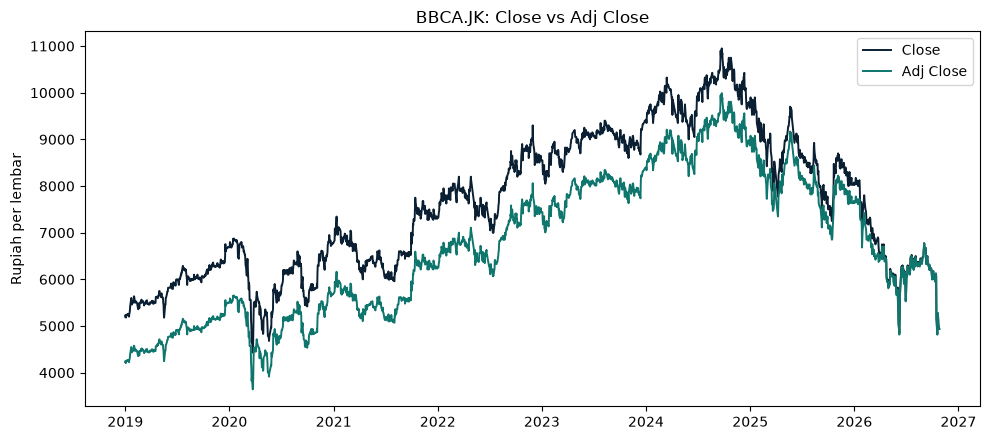

In [6]:
ticker = "BBCA.JK"
subset = prices[prices["ticker"] == ticker].set_index("date")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(subset.index, subset["close"], label="Close", color="#0B1F33", linewidth=1.4)
ax.plot(subset.index, subset["adj_close"], label="Adj Close", color="#0F766E", linewidth=1.4)
ax.set_title(f"{ticker}: Close vs Adj Close")
ax.set_ylabel("Rupiah per lembar")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Simpan hasil pembersihan

Kita menyimpan **hasil olahan** di `data/processed`, bukan menimpa file mentah.
Ini memudahkan audit: file asli tetap ada.

In [7]:
from src.config import SNAPSHOT_CLEAN_FILE, FEATURES_FILE

SNAPSHOT_CLEAN_FILE.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(SNAPSHOT_CLEAN_FILE, index=False)
print("Disimpan:", SNAPSHOT_CLEAN_FILE)

# Fitur harian dibuat di notebook berikutnya; kita cek dulu apakah file sudah ada.
print("Fitur harian ada:", FEATURES_FILE.exists())

Disimpan: C:\Users\53\Documents\data sains\project saham\data\processed\idx_snapshot_clean.csv
Fitur harian ada: False


## Kesimpulan

- File mentah tetap utuh.
- Duplikat dihapus, bukan dirata-ratakan diam-diam.
- Harga tidak valid dibuang; nilai hilang tidak diisi dengan angka karangan.
- `Open Price = 0` diperlakukan sebagai data tidak tersedia.

Lanjut ke `03_feature_engineering.ipynb`.